# M8: Real traffic and delays (BTS on-time data)

**Paper section covered:** none (Part B, work beyond the paper). Extensions E4 (real traffic weights) and E7 (delays).

## Why this milestone
Every weight so far (the paper's, and the operated-only variant of M7) is a count of airline *listings* in OpenFlights, a 2014 snapshot of crowd-sourced route data. The second dataset in the project (`data/kaggle/`) is different in kind: **2.7 million real flights** from the US Bureau of Transportation Statistics (BTS) on-time performance records, with the carrier, origin, destination, day, and departure and arrival delay of every flight. It gives us, for the first time, **real traffic** to test against.

## What the data can and cannot do
| | |
|---|---|
| **Has** | 2,702,218 completed flights; 16 carriers; origin and destination airport; day of month and day of week; departure and arrival delay in minutes |
| **Covers only 70 airports** | the `airports.csv` file lists 365 airports, but flights involve only the 70 busiest: this is the **core** of the network, not the periphery |
| **No date** | only day of month and day of week; several months are pooled together, in an unknown period |
| **No clock times, no aircraft** | so we cannot follow a delay from one flight to the next flight of the same aircraft |
| **Completed flights only** | cancelled and diverted flights carry no delay and are excluded |

So this dataset is a **real-traffic reference for the major airports**. It can validate the OpenFlights network and its weights where the two overlap, measure how concentrated real traffic is, and describe delays; it cannot say anything about small airports (the periphery), or follow delay propagation flight by flight.

## Plan
| Part | Question |
|---|---|
| A | What is in the data? |
| B | Can the 70 BTS airports be matched reliably to OpenFlights? |
| C | How good are the OpenFlights network and weights as a picture of real traffic? |
| D | How concentrated is real traffic, and which ranking finds the airports that matter? Is the major-airport core fragile? |
| E | Delays: hotspots, relation to network structure, and a test for delay transmission |
| F | Verdict, and what changes in earlier milestones |

## 1. Setup

In [1]:
import sys, re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))
import usfn, weighted as wt, attacks as at, cascade as cs

warnings.filterwarnings("ignore")
pd.set_option("display.width", 175)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 100)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
BLUE, RED, GREEN, ORANGE, GREY, PURPLE = "#3b6ea5", "#c05746", "#4d8f5b", "#d99a2b", "#777777", "#8e5ea2"
rng = np.random.default_rng(2025)

airports, routes = usfn.load_openflights()
G0 = usfn.build_country_network(airports, routes)
G, Gop, cshare = wt.build_weightings(G0, routes)
fl_raw = pd.read_csv(ROOT / "data" / "kaggle" / "flights.csv")
bts_ap = pd.read_csv(ROOT / "data" / "kaggle" / "airports.csv")
print(f"OpenFlights network: {G.number_of_nodes()} airports | BTS file: {len(fl_raw):,} flights")

OpenFlights network: 541 airports | BTS file: 2,702,218 flights


## Part A. What is in the data?

flights: 2,702,218 | carriers: 16 | airports used as origin or destination: 70 of 365 in airports.csv
missing values: 0 (cancelled and diverted flights are not in this file)
delay: mean departure 10.5 min, mean arrival 6.7 min; share of flights arriving 15 or more minutes late (the official definition of 'delayed'): 20.7%
flights lose about 3.9 minutes of delay on average between departure and arrival (aircraft make up time in the air)


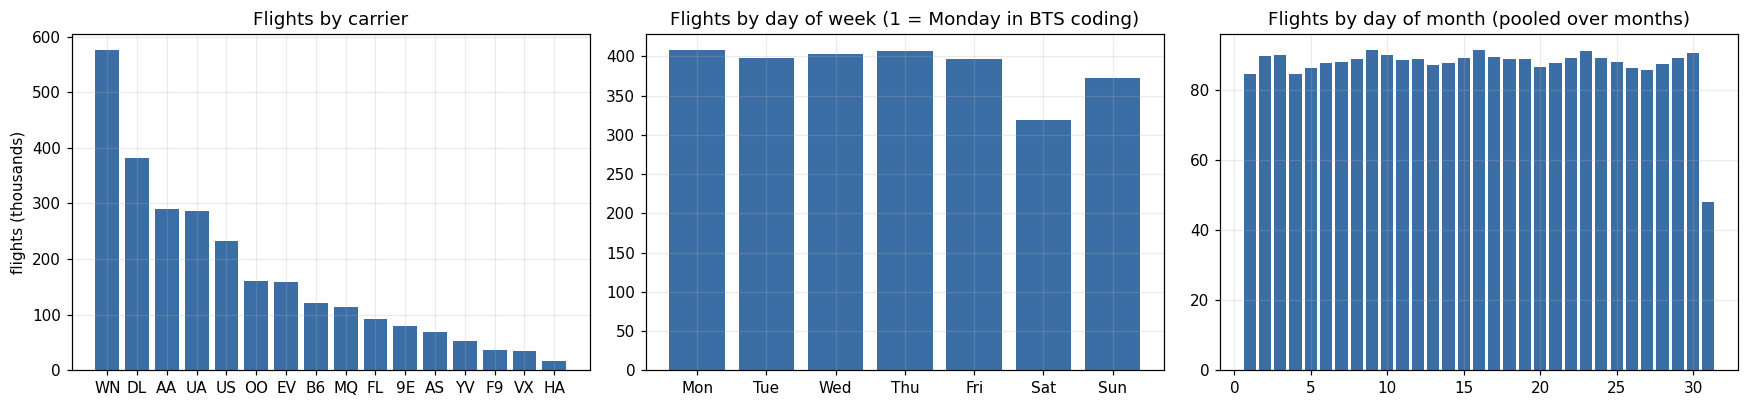

In [2]:
print(f"flights: {len(fl_raw):,} | carriers: {fl_raw.Carrier.nunique()} | airports used as origin or destination: {len(set(fl_raw.OriginAirportID) | set(fl_raw.DestAirportID))} of {len(bts_ap)} in airports.csv")
print(f"missing values: {int(fl_raw.isna().sum().sum())} (cancelled and diverted flights are not in this file)")
print(f"delay: mean departure {fl_raw.DepDelay.mean():.1f} min, mean arrival {fl_raw.ArrDelay.mean():.1f} min; share of flights arriving 15 or more minutes late (the official definition of 'delayed'): {(fl_raw.ArrDelay >= 15).mean():.1%}")
print(f"flights lose about {fl_raw.DepDelay.mean() - fl_raw.ArrDelay.mean():.1f} minutes of delay on average between departure and arrival (aircraft make up time in the air)")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
car = fl_raw.Carrier.value_counts()
axes[0].bar(car.index, car.values / 1e3, color=BLUE); axes[0].set_ylabel("flights (thousands)"); axes[0].set_title("Flights by carrier")
dow = fl_raw.groupby("DayOfWeek").size(); axes[1].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], dow.values / 1e3, color=BLUE); axes[1].set_title("Flights by day of week (1 = Monday in BTS coding)")
dom = fl_raw.groupby("DayofMonth").size(); axes[2].bar(dom.index, dom.values / 1e3, color=BLUE); axes[2].set_title("Flights by day of month (pooled over months)")
for ax in axes: ax.set_xlabel("")
plt.tight_layout(); plt.show()

Two notes. The weekday pattern is as expected (Saturday is the quietest day). The day-of-month counts fall on the 29th to 31st simply because not every month has those days; the number of flights per day of month (about 48,000 to 91,000) tells us that **several months are pooled**, but not which.

## Part B. Matching the BTS airports to OpenFlights

The BTS file identifies airports by a numeric DOT code and a name and city, not by the IATA code that OpenFlights uses, so we must match them. We score every OpenFlights US airport against each BTS airport by the overlap of name and city words (ignoring words like "International"), take the best, and then **check every match by hand**.

In [3]:
STOP = {"airport", "international", "intl", "municipal", "regional", "field", "county", "memorial", "metropolitan", "metro", "the", "of", "and", "at", "airfield", "air", "base"}
toks = lambda s: {t for t in re.findall(r"[a-z0-9]+", s.lower().replace("'", "")) if t not in STOP}
info = airports[airports.country == "United States"].dropna(subset=["iata"]).drop_duplicates("iata").set_index("iata")
cand = info.loc[[n for n in G.nodes if n in info.index]]

ids = sorted(set(fl_raw.OriginAirportID) | set(fl_raw.DestAirportID))
rows = []
for _, r in bts_ap[bts_ap.airport_id.isin(ids)].iterrows():
    bt = toks(r["name"]) | toks(r.city)
    sc = [(len(bt & (toks(c["name"]) | toks(c["city"]))) / max(1, len(bt | (toks(c["name"]) | toks(c["city"])))) + (0.5 if toks(r.city) & toks(c["city"]) else 0), i) for i, c in cand.iterrows()]
    best = max(sc); rows.append({"airport_id": r.airport_id, "BTS name": r["name"], "BTS city": r.city, "state": r.state, "IATA": best[1], "score": round(best[0], 2), "manual fix": ""})
match = pd.DataFrame(rows)

# manual review of all 70 matches found two errors: Columbus OH matched Columbus GA, and San Juan PR (not in the US domestic network) matched an unrelated airport
fix = {11066: "CMH", 14843: None}
for aid, code_ in fix.items():
    match.loc[match.airport_id == aid, "manual fix"] = f"was {match.loc[match.airport_id == aid, 'IATA'].iloc[0]}, now {code_}"
    match.loc[match.airport_id == aid, "IATA"] = code_
match["OpenFlights name"] = [info.loc[i, "name"] if i in info.index else "(not in the US domestic network)" for i in match.IATA]
mp = dict(zip(match.airport_id, match.IATA))
display(match.sort_values("score").head(8)[["BTS name", "BTS city", "IATA", "OpenFlights name", "score", "manual fix"]].style.hide(axis="index"))
print(f"{match.IATA.notna().sum()} of {len(match)} BTS airports matched; unique IATA codes: {match.IATA.nunique()}; the two corrections are listed above")

BTS name,BTS city,IATA,OpenFlights name,score,manual fix
Bradley International,Hartford,BDL,Bradley International Airport,0.250000,
Honolulu International,Honolulu,HNL,Daniel K Inouye International Airport,0.750000,
Luis Munoz Marin International,San Juan,None,(not in the US domestic network),0.830000,"was SBP, now None"
Logan International,Boston,BOS,General Edward Lawrence Logan International Airport,0.900000,
LaGuardia,New York,LGA,La Guardia Airport,0.900000,
Port Columbus International,Columbus,CMH,John Glenn Columbus International Airport,1.000000,"was CSG, now CMH"
Minneapolis-St Paul International,Minneapolis,MSP,Minneapolis-St Paul International/Wold-Chamberlain Airport,1.100000,
Long Beach Airport,Long Beach,LGB,Long Beach /Daugherty Field/ Airport,1.170000,


69 of 70 BTS airports matched; unique IATA codes: 69; the two corrections are listed above


In [4]:
f = fl_raw.copy()
f["o"] = f.OriginAirportID.map(mp); f["d"] = f.DestAirportID.map(mp)
n_drop = int((f.o.isna() | f.d.isna()).sum())
f = f.dropna(subset=["o", "d"]).reset_index(drop=True)
core = sorted(set(f.o) | set(f.d))
print(f"flights to or from San Juan (outside the US domestic network) dropped: {n_drop:,} ({n_drop / len(fl_raw):.1%}); flights kept: {len(f):,}; airports: {len(core)}")

# validation: do real flights run on the edges of the OpenFlights network?
und = f.assign(a=np.minimum(f.o, f.d), b=np.maximum(f.o, f.d)).groupby(["a", "b"]).size().rename("flights").reset_index()
Gc = G.subgraph(core)
of_edges = {frozenset(e) for e in Gc.edges}; bts_edges = {frozenset((r.a, r.b)) for r in und.itertuples()}
both = of_edges & bts_edges
print(f"airport pairs with real flights: {len(bts_edges)} | OpenFlights edges among the same airports: {len(of_edges)} | in both: {len(both)}")
print(f"-> {len(both) / len(bts_edges):.0%} of real flight pairs exist in OpenFlights, and {len(both) / len(of_edges):.0%} of OpenFlights pairs have real flights")

flights to or from San Juan (outside the US domestic network) dropped: 27,627 (1.0%); flights kept: 2,674,591; airports: 69


airport pairs with real flights: 1242 | OpenFlights edges among the same airports: 1229 | in both: 1175
-> 95% of real flight pairs exist in OpenFlights, and 96% of OpenFlights pairs have real flights


**The matching is validated** by an independent check: of the 1,242 airport pairs that have real flights, 1,175 (95%) are edges of the OpenFlights network, and 96% of OpenFlights edges between these airports have real flights. If the matching were wrong this agreement could not be so high. (The two manual corrections, Columbus and San Juan, are shown above; they are the kind of error that an unchecked fuzzy match would have silently introduced.) This is itself a result: **the OpenFlights topology among the major airports is an accurate picture of real air service**, so the structural conclusions of M1 to M6 are not an artefact of bad route data, at least for the core.

## Part C. How good are the OpenFlights weights as a measure of real traffic?
For the 69 airports and their pairs we now have two views of "how much service": the OpenFlights weights (all route rows, and operated-only rows, from M7) and the **real flight counts**. We compare them at the level of airport pairs and of airports.

pairs with real flights: 1242; of these in the OpenFlights network: 1175; with an operated route: 1057
edge level, Spearman: real flights vs all-rows weight 0.60 | vs operated-only weight 0.55


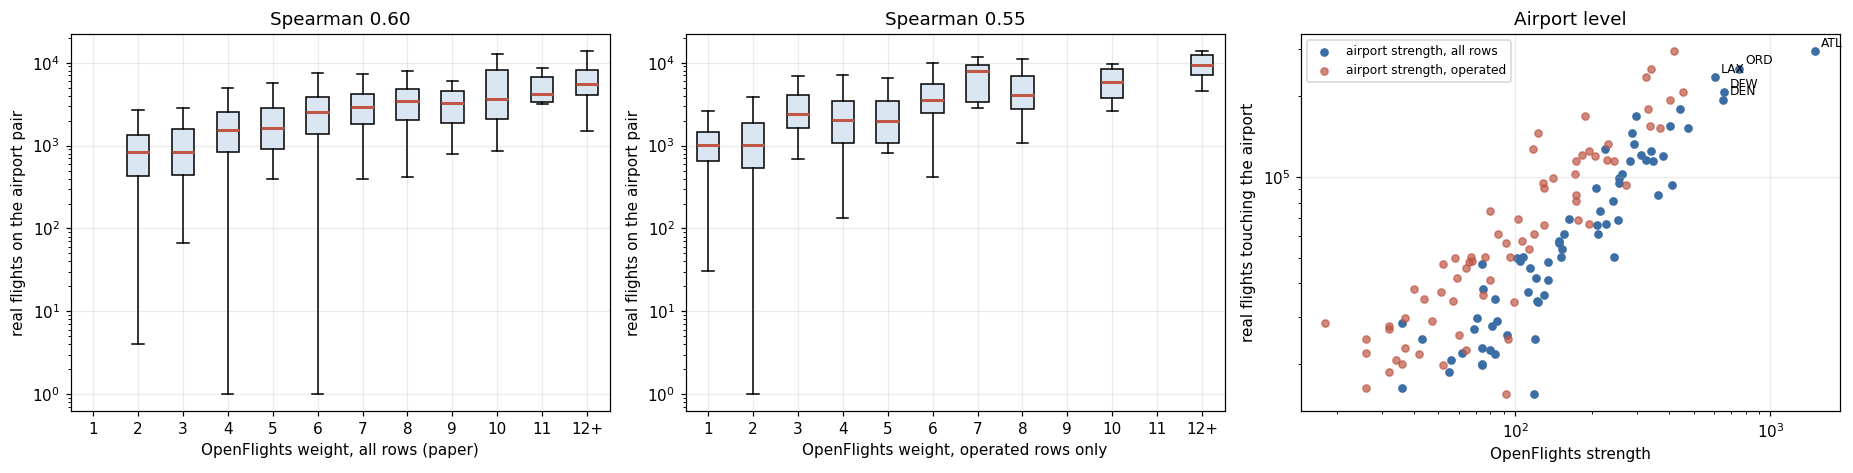

airport level, Spearman with real flights: {'degree': 0.926, 'strength, all rows (paper)': 0.932, 'strength, operated only': 0.902}


,real flights,"strength, all rows","strength, operated",degree
rank,,,,
1,ATL,ATL,DFW,ATL
2,ORD,ORD,ATL,DEN
3,LAX,DFW,DEN,ORD
4,DFW,DEN,CLT,DFW
5,DEN,LAX,ORD,MSP
6,PHX,CLT,LAS,DTW
7,SFO,PHX,PHX,LAS
8,LAS,PHL,LAX,CLT
9,CLT,LAS,PHL,IAH


overlap with the real top 10: {'strength, all rows': 8, 'strength, operated': 8, 'degree': 7}


In [5]:
rows = []
for r in und.itertuples():
    rows.append({"a": r.a, "b": r.b, "flights": r.flights, "w_all": G[r.a][r.b]["weight"] if G.has_edge(r.a, r.b) else 0, "w_op": Gop[r.a][r.b]["weight"] if Gop.has_edge(r.a, r.b) else 0})
E = pd.DataFrame(rows)
inboth = E[E.w_all > 0]; inop = E[E.w_op > 0]
rho_all = spearmanr(inboth.flights, inboth.w_all).statistic; rho_op = spearmanr(inop.flights, inop.w_op).statistic
print(f"pairs with real flights: {len(E)}; of these in the OpenFlights network: {len(inboth)}; with an operated route: {len(inop)}")
print(f"edge level, Spearman: real flights vs all-rows weight {rho_all:.2f} | vs operated-only weight {rho_op:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, col, df, lab in [(axes[0], "w_all", inboth, "OpenFlights weight, all rows (paper)"), (axes[1], "w_op", inop, "OpenFlights weight, operated rows only")]:
    bins = np.minimum(df[col], 12); groups = [df.flights[bins == k].values for k in range(1, 13)]
    ax.boxplot(groups, labels=[str(k) if k < 12 else "12+" for k in range(1, 13)], showfliers=False, patch_artist=True, boxprops=dict(facecolor="#dbe6f3"), medianprops=dict(color=RED, lw=2))
    ax.set_yscale("log"); ax.set_xlabel(lab); ax.set_ylabel("real flights on the airport pair"); ax.set_title(f"Spearman {spearmanr(df.flights, df[col]).statistic:.2f}")
fl_ap = pd.concat([f.o, f.d]).value_counts()
sa = {n: G.degree(n, weight="weight") for n in core}; so = {n: Gop.degree(n, weight="weight") if n in Gop else 0 for n in core}; dg = {n: G.degree(n) for n in core}
axes[2].scatter([sa[n] for n in fl_ap.index], fl_ap.values, s=22, color=BLUE, label="airport strength, all rows"); axes[2].scatter([so[n] for n in fl_ap.index], fl_ap.values, s=22, color=RED, alpha=0.7, label="airport strength, operated")
for n in ["ATL", "ORD", "LAX", "DFW", "DEN"]: axes[2].annotate(n, (sa[n], fl_ap[n]), xytext=(4, 3), textcoords="offset points", fontsize=8)
axes[2].set_xscale("log"); axes[2].set_yscale("log"); axes[2].set_xlabel("OpenFlights strength"); axes[2].set_ylabel("real flights touching the airport"); axes[2].set_title("Airport level"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

ap_rows = {m: spearmanr([fl_ap[n] for n in fl_ap.index], [v[n] for n in fl_ap.index]).statistic for m, v in [("degree", dg), ("strength, all rows (paper)", sa), ("strength, operated only", so)]}
print("airport level, Spearman with real flights:", {k: round(v, 3) for k, v in ap_rows.items()})
top10 = list(fl_ap.index[:10])
rk = {"real flights": top10, "strength, all rows": sorted(core, key=lambda n: -sa[n])[:10], "strength, operated": sorted(core, key=lambda n: -so[n])[:10], "degree": sorted(core, key=lambda n: -dg[n])[:10]}
tt = pd.DataFrame(rk); tt.index = range(1, 11); tt.index.name = "rank"; display(tt)
print("overlap with the real top 10:", {k: len(set(v) & set(top10)) for k, v in rk.items() if k != "real flights"})

In [6]:
only_bts = und[[frozenset((r.a, r.b)) not in of_edges for r in und.itertuples()]].sort_values("flights", ascending=False)
print(f"{len(only_bts)} airport pairs have real flights but are NOT edges of the OpenFlights network; their flights: median {only_bts.flights.median():.0f}, total {only_bts.flights.sum():,} ({only_bts.flights.sum() / und.flights.sum():.1%} of all flights)")
print("largest examples:", ", ".join(f"{r.a}-{r.b} ({r.flights})" for r in only_bts.head(6).itertuples()))
only_of = sorted(of_edges - bts_edges, key=lambda e: -G[tuple(e)[0]][tuple(e)[1]]["weight"])
print(f"{len(only_of)} OpenFlights edges among these airports have no real flights in the BTS file (probably regional or seasonal service, or the carrier is not in this 16-carrier file)")

67 airport pairs have real flights but are NOT edges of the OpenFlights network; their flights: median 194, total 15,467 (0.6% of all flights)
largest examples: SDF-STL (761), MEM-PHL (678), BNA-MEM (593), BOS-ORF (583), MEM-MKE (579), ANC-SFO (543)
54 OpenFlights edges among these airports have no real flights in the BTS file (probably regional or seasonal service, or the carrier is not in this 16-carrier file)


**Reading this.**
- **At the airport level the OpenFlights numbers are good proxies for real traffic:** the Spearman correlation with real flights is 0.93 for the paper's all-rows strength, 0.93 for degree, and 0.90 for operated-only strength. The paper's weights are slightly *better* than the operated-only ones here.
- **At the level of individual routes they are only moderate** (0.60 and 0.55): a pair served by one airline with many daily flights can be heavier in reality than a pair listed by three airlines with one flight each, and OpenFlights counts airlines, not frequencies. The boxplots show a clear upward trend with large spread.
- **This corrects part of the M7 reading.** M7 showed that ATL's weight is 72% codeshare and concluded that the paper's weights "partly rank airline alliances". That is true of the *listings*, but in **real traffic ATL is genuinely the busiest airport**: first in real flights (about 148,000 departures against 127,000 at ORD, 17% more). The all-rows weights put ATL first, correctly, and the operated-only weights put it second to DFW, *incorrectly*. So the codeshare inflation does not distort the top of the ranking, because codeshare listings go with large carriers' big hubs; the operated-only count (airlines per route, not flights) underrates a hub dominated by one carrier with high frequency.
- **The 67 pairs with real flights but no OpenFlights edge are marginal** (median 194 flights each, 0.6% of all flights in total; the largest are SDF-STL, MEM-PHL and BNA-MEM): the OpenFlights snapshot is a good but not perfect picture.

## Part D. How concentrated is real traffic, and which airports matter?

### D1. Traffic concentration
A flight touches an airport if it departs from or lands at it. How much of all traffic touches the busiest airports?

share of all flights that touch the busiest k airports: {1: 0.11, 3: 0.284, 5: 0.413, 10: 0.629, 20: 0.871}


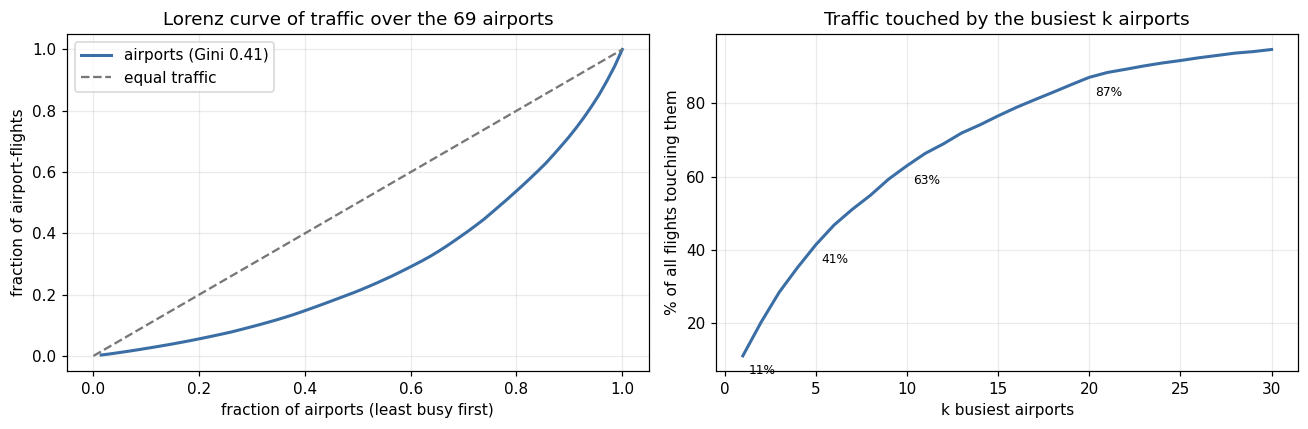

In [7]:
ord_f = list(fl_ap.index)
def touch(S):
    S = set(S); return float((f.o.isin(S) | f.d.isin(S)).mean())
ks = np.arange(1, 31)
curve_real = np.array([touch(ord_f[:k]) for k in ks])
print("share of all flights that touch the busiest k airports:", {k: round(curve_real[k - 1], 3) for k in (1, 3, 5, 10, 20)})

x = np.sort(fl_ap.values.astype(float)); lor = np.cumsum(x) / x.sum()
gini = (len(x) + 1 - 2 * (np.cumsum(x).sum() / x.sum())) / len(x)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(np.arange(1, len(x) + 1) / len(x), lor, color=BLUE, lw=2, label=f"airports (Gini {gini:.2f})"); axes[0].plot([0, 1], [0, 1], color=GREY, ls="--", label="equal traffic")
axes[0].set_xlabel("fraction of airports (least busy first)"); axes[0].set_ylabel("fraction of airport-flights"); axes[0].set_title("Lorenz curve of traffic over the 69 airports"); axes[0].legend()
axes[1].plot(ks, 100 * curve_real, color=BLUE, lw=2); axes[1].set_xlabel("k busiest airports"); axes[1].set_ylabel("% of all flights touching them"); axes[1].set_title("Traffic touched by the busiest k airports")
for k in (1, 5, 10, 20): axes[1].annotate(f"{100 * curve_real[k - 1]:.0f}%", (k, 100 * curve_real[k - 1]), xytext=(4, -12), textcoords="offset points", fontsize=8)
plt.tight_layout(); plt.show()

Traffic is strongly concentrated: **ATL alone touches 11% of all flights, the busiest 5 airports 41%, the busiest 10 63%, and the busiest 20 87%.** Even among these 69 major airports (Gini coefficient 0.41) the busiest 10 (14% of the airports) carry nearly two thirds of the traffic. This is the real-data version of the "service is more concentrated than airports" result of M7.

### D2. Which ranking finds the airports that carry the traffic?
Suppose an attacker, or a planner worried about disruption, ranks airports by some structural measure and takes the top k. How much real traffic touches those k airports, compared with the ideal choice (the k busiest, by real flights) and a random choice?

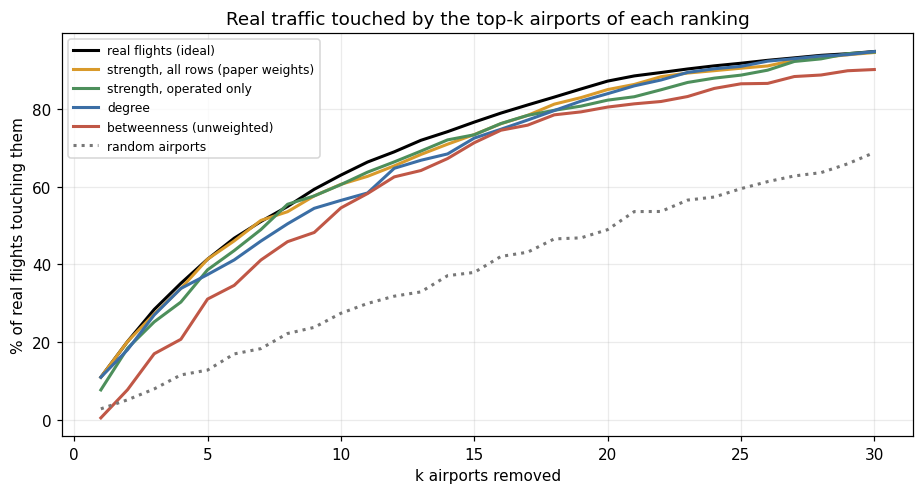

,real flights (ideal),"strength, all rows (paper weights)","strength, operated only",degree,betweenness (unweighted),random airports
top 5,41.3%,41.3%,38.6%,37.4%,31.1%,12.9%
top 10,62.9%,60.6%,60.5%,56.4%,54.5%,27.4%
top 20,87.1%,84.9%,82.2%,83.8%,80.4%,48.9%


In [8]:
bc_full = nx.betweenness_centrality(G)
rankings = {"real flights (ideal)": ord_f, "strength, all rows (paper weights)": sorted(core, key=lambda n: -sa[n]), "strength, operated only": sorted(core, key=lambda n: -so[n]),
            "degree": sorted(core, key=lambda n: -dg[n]), "betweenness (unweighted)": sorted(core, key=lambda n: -bc_full[n])}
rand_curve = np.mean([[touch(list(rng.choice(core, k, replace=False))) for k in ks] for _ in range(60)], axis=0)
curves = {m: np.array([touch(r[:k]) for k in ks]) for m, r in rankings.items()}

fig, ax = plt.subplots(figsize=(8.5, 4.6))
colors = {"real flights (ideal)": "black", "strength, all rows (paper weights)": ORANGE, "strength, operated only": GREEN, "degree": BLUE, "betweenness (unweighted)": RED}
for m, c in curves.items(): ax.plot(ks, 100 * c, color=colors[m], lw=2, label=m)
ax.plot(ks, 100 * rand_curve, color=GREY, ls=":", lw=2, label="random airports"); ax.set_xlabel("k airports removed"); ax.set_ylabel("% of real flights touching them"); ax.set_title("Real traffic touched by the top-k airports of each ranking"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
tab = pd.DataFrame({m: [f"{100 * c[k - 1]:.1f}%" for k in (5, 10, 20)] for m, c in curves.items()}, index=["top 5", "top 10", "top 20"]); tab["random airports"] = [f"{100 * rand_curve[k - 1]:.1f}%" for k in (5, 10, 20)]
display(tab)

**Reading this.**
- **Strength is nearly as good as knowing the real traffic**: the top 10 by strength touch about 61% of flights against 63% for the real top 10, and the random choice only 28%. Degree is a little worse (56%) and **betweenness is the worst of the structural rankings** (55%; and only 31% at k = 5 against 41%).
- This is independent, real-data support for the M7 conclusion that the best attack for *service* is strength-based and not betweenness-based, and it explains why: betweenness picks gateways (ANC, SEA) whose importance is structural, not volume.
- The two OpenFlights weightings do about equally well at k = 10, and the paper's all-rows weights are better at k = 5 (41.3%, equal to the ideal) and k = 20.

### D3. Is the major-airport core fragile?
M5 found the network collapses under targeted attack. Where does that fragility live: in the hub core or in the dependence of the periphery on the hubs? The BTS file lets us build a core network from *real* flights (69 airports, any pair with a flight), and the OpenFlights graph restricted to the same airports gives a second view.

core from real flights: 69 airports, 1242 edges, mean degree 36.0, density 0.53
OpenFlights restricted to the same airports: 69 airports, 1229 edges, density 0.52 (the whole network has density 0.019)


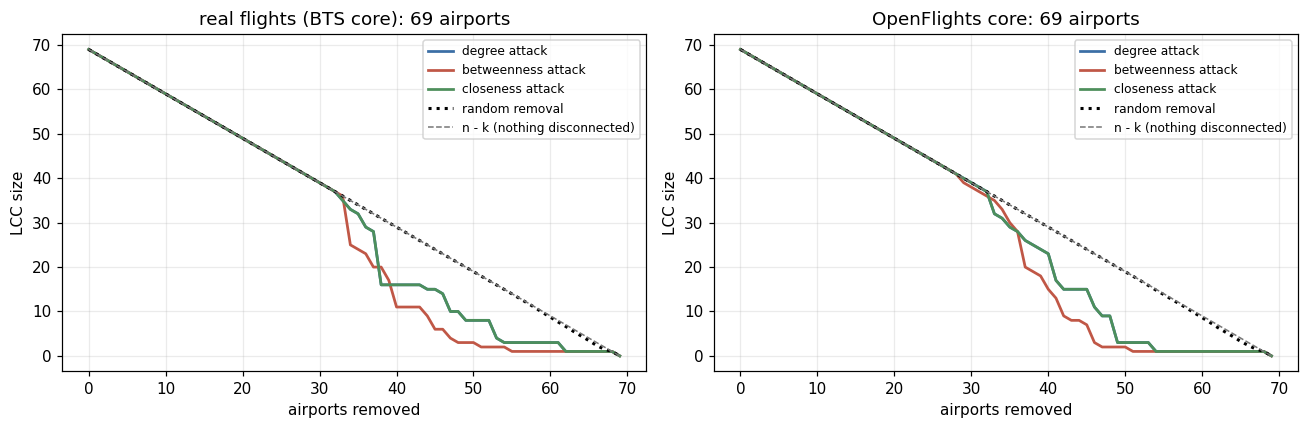

network,attack,LCC after 5 removals,after 10,removals to halve the LCC
real flights (BTS core),degree,64.000000,59.000000,34
real flights (BTS core),betweenness,64.000000,59.000000,34
real flights (BTS core),closeness,64.000000,59.000000,34
real flights (BTS core),random (mean of 100),64.000000,59.000000,35
OpenFlights core,degree,64.000000,59.000000,33
OpenFlights core,betweenness,64.000000,59.000000,34
OpenFlights core,closeness,64.000000,59.000000,33
OpenFlights core,random (mean of 100),64.000000,59.000000,35


In [9]:
Gb = nx.Graph()
for r in und.itertuples(): Gb.add_edge(r.a, r.b, weight=r.flights)
Gcore = G.subgraph(core).copy()
print(f"core from real flights: {Gb.number_of_nodes()} airports, {Gb.number_of_edges()} edges, mean degree {2 * Gb.number_of_edges() / Gb.number_of_nodes():.1f}, density {nx.density(Gb):.2f}")
print(f"OpenFlights restricted to the same airports: {Gcore.number_of_nodes()} airports, {Gcore.number_of_edges()} edges, density {nx.density(Gcore):.2f} (the whole network has density {nx.density(G):.3f})")

rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, g) in zip(axes, [("real flights (BTS core)", Gb), ("OpenFlights core", Gcore)]):
    n = g.number_of_nodes(); nodes_g = list(g.nodes)
    for m, c in [("degree", BLUE), ("betweenness", RED), ("closeness", GREEN)]:
        o = at.static_order(g, m); l, _, _ = at.percolation_curves(g, o); ax.plot(range(n + 1), l, color=c, lw=1.8, label=f"{m} attack")
        rows.append({"network": name, "attack": m, "LCC after 5 removals": int(l[5]), "after 10": int(l[10]), "removals to halve the LCC": at.k_to_reach(l, n, .5)})
    rl = np.mean([at.percolation_curves(g, list(rng.permutation(nodes_g)))[0] for _ in range(100)], axis=0)
    ax.plot(range(n + 1), rl, color="black", ls=":", lw=2, label="random removal"); ax.plot(range(n + 1), n - np.arange(n + 1), color=GREY, ls="--", lw=1, label="n - k (nothing disconnected)")
    rows.append({"network": name, "attack": "random (mean of 100)", "LCC after 5 removals": round(rl[5], 1), "after 10": round(rl[10], 1), "removals to halve the LCC": at.k_to_reach(rl, n, .5)})
    ax.set_xlabel("airports removed"); ax.set_ylabel("LCC size"); ax.set_title(f"{name}: {n} airports"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
pd.DataFrame(rows).style.hide(axis="index")

**Reading this.** The major-airport core is **not fragile at all**: removing the top 5 or top 10 airports by any strategy leaves *every other airport connected* (LCC = 64 after 5 removals and 59 after 10, exactly n - k), and even the targeted curves hug the "nothing disconnected" line; halving the LCC takes about 34 removals whichever strategy is used, just like random removal. The same holds for the OpenFlights graph restricted to these airports, so this is not a property of one dataset. The reason is simple: the core is almost a complete graph (mean degree 36 of 68 possible), so it is full of redundant paths. (Only after about 32 removals, roughly half of the core, do targeted attacks begin to fragment what is left, and then quickly; random removal never does.)

**This pins down where the network's fragility lives.** In M5, removing a handful of airports fragmented the *whole* network (LCC fell to 366 of 541 after 5 betweenness removals). Here, with the periphery removed, the same attack does nothing to connectivity. So the fragility is a property of the **periphery's dependence on a few hubs and gateways**: hundreds of small airports connect to the network only through a few hubs. The core's redundancy does not protect the periphery. (What the core *does* lose when hubs go is **traffic**: Part D1 and D2 show that removing the top 10 airports touches about 63% of flights.)

## Part E. Delays

### E1. Which airports are delay hotspots?

,city,flights,mean_dep,mean_arr,late
o,,,,,
MDW,Chicago,99260,16.1,7.6,22.1%
ORD,Chicago,254096,15.7,9.8,23.0%
EWR,Newark,127089,14.6,12.2,27.4%
DEN,Denver,194178,14.5,8.0,22.6%
DFW,Dallas-Fort Worth,207473,14.1,5.6,18.9%
BWI,Baltimore,102637,13.7,6.3,20.4%
JFK,New York,115417,13.7,10.5,25.2%
SFO,San Francisco,168339,13.5,13.3,28.7%
ANC,Anchorage,15411,1.7,-1.4,14.6%


range of mean departure delay across the 69 airports: 1.7 to 16.1 min (system mean 10.5)


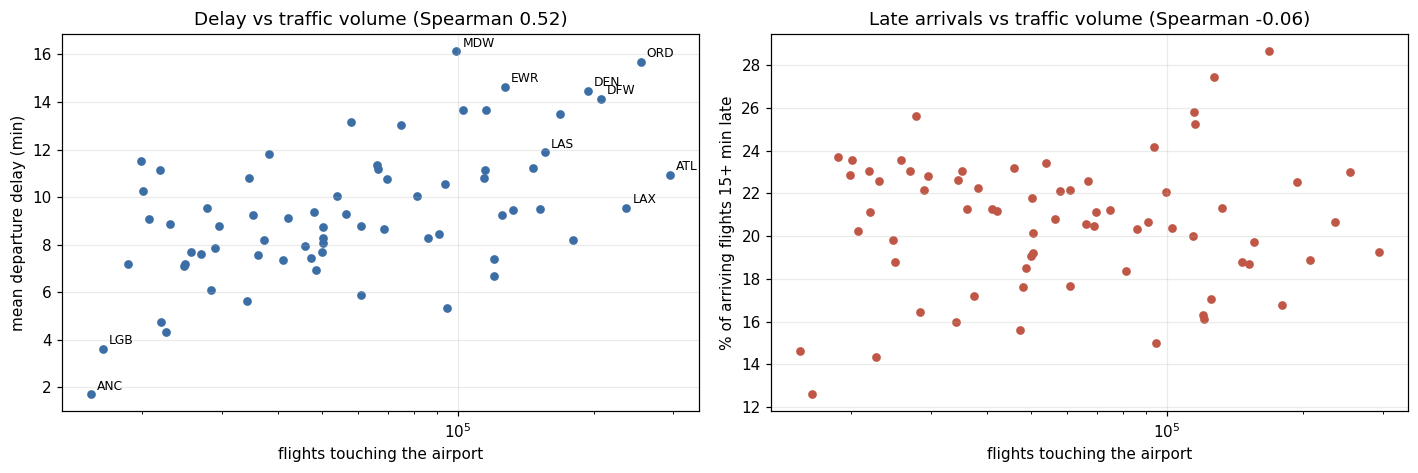

In [10]:
dep = f.groupby("o").agg(mean_dep=("DepDelay", "mean"), n_dep=("DepDelay", "size"))
arr = f.groupby("d").agg(mean_arr=("ArrDelay", "mean"), late=("ArrDelay", lambda s: (s >= 15).mean()))
D = dep.join(arr); D["flights"] = fl_ap.reindex(D.index)
D["city"] = [info.loc[n, "city"] for n in D.index]
show = pd.concat([D.sort_values("mean_dep", ascending=False).head(8), D.sort_values("mean_dep").head(5)])
display(show[["city", "flights", "mean_dep", "mean_arr", "late"]].style.format({"mean_dep": "{:.1f}", "mean_arr": "{:.1f}", "late": "{:.1%}"}))
print(f"range of mean departure delay across the 69 airports: {D.mean_dep.min():.1f} to {D.mean_dep.max():.1f} min (system mean {f.DepDelay.mean():.1f})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]; ax.scatter(D.flights, D.mean_dep, s=22, color=BLUE)
for n in ["ORD", "MDW", "EWR", "DEN", "ATL", "DFW", "ANC", "LGB", "LAX", "LAS"]: ax.annotate(n, (D.flights[n], D.mean_dep[n]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("flights touching the airport"); ax.set_ylabel("mean departure delay (min)"); ax.set_title(f"Delay vs traffic volume (Spearman {spearmanr(D.flights, D.mean_dep).statistic:.2f})")
ax = axes[1]; ax.scatter(D.flights, 100 * D.late, s=22, color=RED); ax.set_xscale("log"); ax.set_xlabel("flights touching the airport"); ax.set_ylabel("% of arriving flights 15+ min late"); ax.set_title(f"Late arrivals vs traffic volume (Spearman {spearmanr(D.flights, D.late).statistic:.2f})")
plt.tight_layout(); plt.show()

Delay hotspots are the big hubs and busy Northeast, Midwest and California airports: **MDW, ORD, EWR, DEN, DFW, BWI, JFK and SFO** have the highest mean departure delays (13.5 to 16.1 minutes), while ANC, LGB, OGG and TUS have the lowest (under 5 minutes). Mean departure delay rises with traffic volume (Spearman 0.52), but the *share of late arrivals* does not (about 0): busy airports have longer waits on departure, not more arrivals that miss the 15-minute mark.

### E2. Do the structurally important airports have more delay?
We relate each airport's delay to its position in the **OpenFlights network** (degree, strength, betweenness, PageRank, all computed on the full 541-airport network) and to its **cascade danger** from M6 (the largest threshold at which its failure still triggers a network-wide avalanche).

In [11]:
Cc = cs.Cascade(G)
tgrid = np.round(np.arange(0.02, 0.4001, 0.005), 3)
t_c = {}
for i, n in enumerate(Cc.nodes):
    if n in D.index:
        ok = [t for t in tgrid if Cc.run([i], Cc.need(t))[0].sum() >= 0.5 * Cc.n]; t_c[n] = max(ok) if ok else 0.0
pr = nx.pagerank(G, weight=None)
measures = {"real flights": D.flights.to_dict(), "degree (OpenFlights)": dg, "strength (OpenFlights)": sa, "betweenness (OpenFlights)": bc_full, "PageRank (OpenFlights)": pr, "cascade danger t_c (M6)": t_c}
rows = []
for m, v in measures.items():
    xs = [v[n] for n in D.index]
    r1 = spearmanr(D.mean_dep, xs); r2 = spearmanr(D.late, xs)
    rows.append({"measure": m, "vs mean departure delay": r1.statistic, "p": r1.pvalue, "vs share of late arrivals": r2.statistic, "p (late)": r2.pvalue})
cor = pd.DataFrame(rows); cor.style.hide(axis="index").format({"vs mean departure delay": "{:+.2f}", "p": "{:.3f}", "vs share of late arrivals": "{:+.2f}", "p (late)": "{:.3f}"})

measure,vs mean departure delay,p,vs share of late arrivals,p (late)
real flights,+0.52,0.000,-0.06,0.614
degree (OpenFlights),+0.48,0.000,-0.10,0.437
strength (OpenFlights),+0.48,0.000,-0.08,0.517
betweenness (OpenFlights),+0.26,0.031,-0.33,0.006
PageRank (OpenFlights),+0.41,0.000,-0.18,0.145
cascade danger t_c (M6),+0.27,0.024,-0.26,0.034


**Reading this.**
- Mean departure delay is **clearly related to size and connectivity** (Spearman about 0.5 with real flights, degree and strength; 0.41 with PageRank), so the busy, well-connected hubs are the slow ones.
- It is only **weakly related to betweenness (0.26) and to cascade danger (0.27)**, the two measures that capture structural *criticality*, and the share of late arrivals is *negatively* related to both (-0.33 and -0.26): gateways like ANC are structurally critical but among the most punctual airports. Structural criticality (for connectivity) and operational congestion (for delay) are different things.
- The airports whose failure would collapse the network (LAS, MSP, DFW, see M6) are not especially late.

### E3. Carriers, weekdays, and days of the month

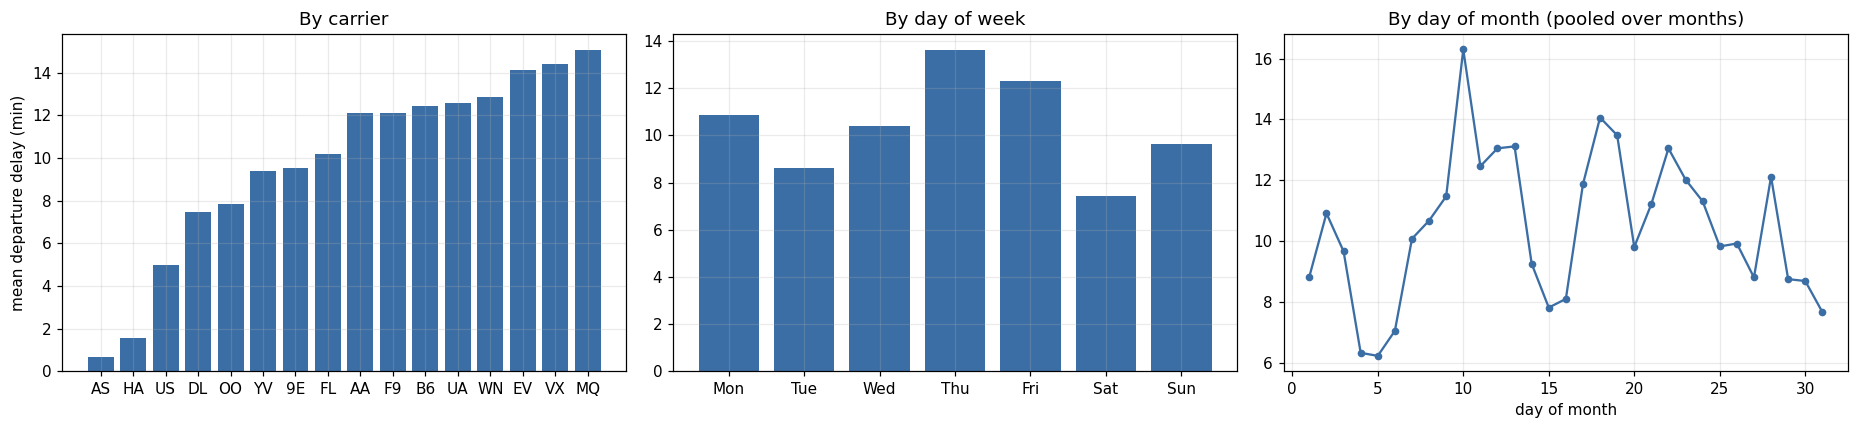

carrier range of mean departure delay: 0.7 (AS) to 15.1 (MQ) min; weekday range: 7.4 to 13.6 min; day-of-month range: 6.2 to 16.3 min


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
cd = f.groupby("Carrier").agg(dep=("DepDelay", "mean"), late=("ArrDelay", lambda s: (s >= 15).mean()), n=("DepDelay", "size")).sort_values("dep")
axes[0].bar(cd.index, cd.dep, color=BLUE); axes[0].set_ylabel("mean departure delay (min)"); axes[0].set_title("By carrier")
wd = f.groupby("DayOfWeek").DepDelay.mean(); axes[1].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], wd.values, color=BLUE); axes[1].set_title("By day of week")
dm = f.groupby("DayofMonth").DepDelay.mean(); axes[2].plot(dm.index, dm.values, "o-", color=BLUE, ms=4); axes[2].set_title("By day of month (pooled over months)"); axes[2].set_xlabel("day of month")
for ax in axes[:2]: ax.set_xlabel("")
plt.tight_layout(); plt.show()
print(f"carrier range of mean departure delay: {cd.dep.min():.1f} ({cd.dep.idxmin()}) to {cd.dep.max():.1f} ({cd.dep.idxmax()}) min; weekday range: {wd.min():.1f} to {wd.max():.1f} min; day-of-month range: {dm.min():.1f} to {dm.max():.1f} min")

**Carriers differ enormously** (mean departure delay from 0.7 minutes for AS to 15.1 for MQ), so a carrier effect is a large part of what makes an airport slow; the weekday effect is smaller (7.4 to 13.6 minutes) and the day-of-month pattern (6.2 to 16.3) is noisy because it pools different months and so mixes unrelated weather.

### E4. A test for delay transmission within carriers
The file has no clock times or aircraft identifiers, so we **cannot follow a delay from one flight to the next flight of the same aircraft**. What we can test is the aggregate signature of such transmission: at a given airport, does a carrier whose *inbound* flights are late also have *late outbound* flights, beyond what the airport's general congestion and the carrier's general punctuality explain? We compare, over (airport, carrier) cells, the carrier's mean outbound departure delay with (i) the same carrier's mean inbound arrival delay at that airport and (ii) the mean inbound arrival delay of *all other* carriers there (airport-wide conditions), with airport and carrier fixed effects.

In [13]:
out_ = f.groupby(["o", "Carrier"]).agg(od=("DepDelay", "mean"), no=("DepDelay", "size")).reset_index().rename(columns={"o": "ap"})
in_ = f.groupby(["d", "Carrier"]).agg(ia=("ArrDelay", "mean"), ni=("ArrDelay", "size"), s_c=("ArrDelay", "sum")).reset_index().rename(columns={"d": "ap"})
cell = out_.merge(in_, on=["ap", "Carrier"]); cell = cell[(cell.no >= 300) & (cell.ni >= 300)]
tot = f.groupby("d").ArrDelay.agg(["sum", "count"]); cell = cell.merge(tot, left_on="ap", right_index=True)
cell["io"] = (cell["sum"] - cell["s_c"]) / (cell["count"] - cell["ni"])
cell = cell.reset_index(drop=True)
print(f"cells (airport x carrier with at least 300 inbound and 300 outbound flights): {len(cell)}, airports {cell.ap.nunique()}, carriers {cell.Carrier.nunique()}")

def fit(df, cols, cluster):
    d_ = pd.concat([pd.get_dummies(df[cluster], drop_first=True), pd.get_dummies(df.Carrier, drop_first=True)], axis=1).values.astype(float)
    y = df.od.values.astype(float); w = np.sqrt(df.no.values)
    Z = np.hstack([df[cols].values.astype(float), d_, np.ones((len(df), 1))])
    beta = np.linalg.lstsq(Z * w[:, None], y * w, rcond=None)[0]; fitv = (Z * w[:, None]) @ beta
    return beta[:len(cols)], 1 - ((y * w - fitv) ** 2).sum() / ((y * w - np.average(y * w)) ** 2).sum()

models = {"inbound, same carrier only": ["ia"], "inbound, other carriers only": ["io"], "both": ["ia", "io"]}
res = {k: fit(cell, c, "ap") for k, c in models.items()}
# cluster bootstrap over airports
aps = cell.ap.unique(); groups = {a: cell[cell.ap == a] for a in aps}; boots = []
for b in range(300):
    pick = rng.choice(aps, len(aps), replace=True)
    d_ = pd.concat([groups[a].assign(ap=f"{a}#{j}") for j, a in enumerate(pick)], ignore_index=True)
    boots.append(fit(d_, ["ia", "io"], "ap")[0])
boots = np.array(boots); ci = np.percentile(boots, [2.5, 97.5], axis=0)
out = pd.DataFrame([{"model": k, "coefficient on same-carrier inbound delay": (v[0][0] if "ia" in models[k] else np.nan), "coefficient on other carriers' inbound delay": (v[0][-1] if "io" in models[k] else np.nan), "R2 (with fixed effects)": v[1]} for k, v in res.items()])
display(out.style.hide(axis="index").format(precision=3, na_rep="-"))
print(f"joint model, 95% bootstrap interval (by airport): same-carrier inbound {ci[0, 0]:.2f} to {ci[1, 0]:.2f}; other carriers' inbound {ci[0, 1]:.2f} to {ci[1, 1]:.2f}")
print(f"raw correlation of the carrier's outbound delay with its inbound delay: {np.corrcoef(cell.od, cell.ia)[0, 1]:.2f}; with other carriers' inbound delay: {np.corrcoef(cell.od, cell.io)[0, 1]:.2f}")

cells (airport x carrier with at least 300 inbound and 300 outbound flights): 624, airports 69, carriers 16


model,coefficient on same-carrier inbound delay,coefficient on other carriers' inbound delay,R2 (with fixed effects)
"inbound, same carrier only",0.442,-,0.939
"inbound, other carriers only",-,-0.283,0.924
both,0.529,0.482,0.940


joint model, 95% bootstrap interval (by airport): same-carrier inbound 0.43 to 0.62; other carriers' inbound 0.10 to 0.83
raw correlation of the carrier's outbound delay with its inbound delay: 0.69; with other carriers' inbound delay: 0.10


**Reading this.** In the joint model the outbound delay of a carrier rises by about **0.5 minutes per minute of its own inbound delay** (95% interval 0.44 to 0.62, well determined) and by about **0.5 per minute of other carriers' inbound delay** at the same airport (but this one is imprecise: 0.08 to 0.84), on top of airport and carrier effects. So there is a clear **carrier-specific component** (consistent with delays travelling with a carrier's aircraft and crews) and probably an **airport-wide component** (consistent with shared congestion and weather) whose size the data cannot pin down. The two inbound delays are correlated, which is why the other-carriers-only model even gives a negative number (-0.28) once the fixed effects are applied; the joint model is the one to read.

An honest limit: this is a **cross-sectional association over cells averaged across many days**, not a measurement of propagation. It shows that where a carrier's arrivals run late its departures run late too, not that one delay *caused* the other. Establishing propagation chains needs flight-by-flight aircraft rotations (tail numbers and times), which this file does not have.

### E5. Do delayed airports connect to delayed airports?
A last network question: across real flights, is a flight's origin delay level correlated with its destination's delay level more than chance (regional delay clusters)? We correlate airport mean delays across flights and compare with shuffling the delays among airports.

In [14]:
m = D.mean_dep.to_dict()
x = f.o.map(m).values; y = f.d.map(m).values
r_obs = np.corrcoef(x, y)[0, 1]
nodes_c = list(m); vals = np.array([m[n] for n in nodes_c])
null = []
for _ in range(500):
    perm = dict(zip(nodes_c, rng.permutation(vals)))
    null.append(np.corrcoef(f.o.map(perm).values, f.d.map(perm).values)[0, 1])
null = np.array(null)
print(f"correlation between the mean delay of a flight's origin airport and its destination airport: {r_obs:.3f}; shuffled airports: {null.mean():.3f} +/- {null.std():.3f} (z = {(r_obs - null.mean()) / null.std():+.1f})")

correlation between the mean delay of a flight's origin airport and its destination airport: -0.013; shuffled airports: -0.024 +/- 0.023 (z = +0.5)


**There is no evidence of such clustering**: the observed correlation (-0.01) is within the shuffled range (-0.03 +/- 0.02, z = +0.5). In the traffic-weighted core, whether an airport is delayed tells us nothing about whether the airports it connects to are delayed; this is also what we would expect from a near-complete graph, where everyone connects to everyone.

## Part F. Verdict, and what changes in earlier milestones

In [15]:
rho_str = ap_rows["strength, all rows (paper)"]; rho_op_ = ap_rows["strength, operated only"]
verdict = pd.DataFrame([
    ("The OpenFlights network is a reliable picture of real service (M0, M1)",
     f"Yes for the major airports: {len(both)} of {len(bts_edges)} real flight pairs ({len(both) / len(bts_edges):.0%}) are OpenFlights edges, and {len(both) / len(of_edges):.0%} of OpenFlights edges have real flights", "validated (for the core)"),
    ("The paper's edge weight measures service",
     f"Moderately: Spearman {rho_all:.2f} with real flights per pair, but {rho_str:.2f} per airport, better than the operated-only weights ({rho_op_:.2f}); ATL really is the busiest airport", "moderate proxy; M7's alliance-inflation reading corrected"),
    ("Service is more concentrated than airports (M7)",
     f"Confirmed with real flights: the busiest 10 of 69 airports touch {100 * curve_real[9]:.0f}% of all flights (Gini {gini:.2f})", "confirmed"),
    ("Strength-based rankings find the traffic-carrying airports; betweenness does not (M7)",
     f"Top 10 by strength touch {100 * curves['strength, all rows (paper weights)'][9]:.0f}% of flights (ideal {100 * curve_real[9]:.0f}%); by betweenness {100 * curves['betweenness (unweighted)'][9]:.0f}%", "confirmed"),
    ("The network is fragile to targeted attack (M5)",
     "True for the periphery's dependence on hubs; the major-airport core (69 airports, density 0.5) is completely redundant: no removal disconnects it (checked on both real flights and OpenFlights)", "refined: fragility lives in the periphery"),
    ("Delays and network structure",
     f"Mean departure delay rises with traffic and connectivity (Spearman {cor.iloc[0, 1]:.2f} with flights), only weakly with betweenness ({cor.iloc[3, 1]:.2f}) and cascade danger ({cor.iloc[5, 1]:.2f}); busy airports are slower but do not have more late arrivals; no delay clustering between connected airports", "new finding"),
    ("Delay transmission",
     f"Same-carrier inbound delay carries about {res['both'][0][0]:.1f} minute per minute into outbound delay (95% interval {ci[0, 0]:.2f} to {ci[1, 0]:.2f}); the airport-wide share is imprecise; an association rather than proof of propagation; the file cannot trace aircraft", "association only"),
], columns=["question", "what we find", "status"])
verdict.style.hide(axis="index").format(escape="html").set_properties(subset=["question", "what we find"], **{"text-align": "left", "white-space": "normal"})

question,what we find,status
"The OpenFlights network is a reliable picture of real service (M0, M1)","Yes for the major airports: 1175 of 1242 real flight pairs (95%) are OpenFlights edges, and 96% of OpenFlights edges have real flights",validated (for the core)
The paper's edge weight measures service,"Moderately: Spearman 0.60 with real flights per pair, but 0.93 per airport, better than the operated-only weights (0.90); ATL really is the busiest airport",moderate proxy; M7's alliance-inflation reading corrected
Service is more concentrated than airports (M7),Confirmed with real flights: the busiest 10 of 69 airports touch 63% of all flights (Gini 0.41),confirmed
Strength-based rankings find the traffic-carrying airports; betweenness does not (M7),Top 10 by strength touch 61% of flights (ideal 63%); by betweenness 55%,confirmed
The network is fragile to targeted attack (M5),"True for the periphery's dependence on hubs; the major-airport core (69 airports, density 0.5) is completely redundant: no removal disconnects it (checked on both real flights and OpenFlights)",refined: fragility lives in the periphery
Delays and network structure,"Mean departure delay rises with traffic and connectivity (Spearman 0.52 with flights), only weakly with betweenness (0.26) and cascade danger (0.27); busy airports are slower but do not have more late arrivals; no delay clustering between connected airports",new finding
Delay transmission,Same-carrier inbound delay carries about 0.5 minute per minute into outbound delay (95% interval 0.43 to 0.62); the airport-wide share is imprecise; an association rather than proof of propagation; the file cannot trace aircraft,association only


## Checks

In [16]:
assert len(fl_raw) == 2702218 and len(match) == 70 and match.IATA.notna().sum() == 69 and match.IATA.nunique() == 69
assert mp[11066] == "CMH" and mp[14843] is None and mp[10397] == "ATL" and mp[13930] == "ORD" and mp[12892] == "LAX"
assert len(f) == len(fl_raw) - n_drop and 0.009 < n_drop / len(fl_raw) < 0.011
assert len(both) / len(bts_edges) > 0.9 and len(both) / len(of_edges) > 0.9                                   # topology validated
assert 0.4 < rho_op < rho_all < 0.8                                                                          # edge-level proxies are moderate, all-rows better
assert ap_rows["strength, all rows (paper)"] > ap_rows["strength, operated only"] and min(ap_rows.values()) > 0.85
assert list(fl_ap.index[:2]) == ["ATL", "ORD"] and fl_ap["ATL"] > fl_ap["ORD"]
assert 0.09 < curve_real[0] < 0.13 and 0.55 < curve_real[9] < 0.7
assert curves["strength, all rows (paper weights)"][9] > curves["degree"][9] > curves["betweenness (unweighted)"][9] > rand_curve[9] * 1.5
assert curves["betweenness (unweighted)"][4] < curves["strength, all rows (paper weights)"][4] - 0.05
# the core is fully redundant: removing 10 airports by any strategy leaves everyone else connected
for g_ in (Gb, Gcore):
    n_ = g_.number_of_nodes()
    for m_ in ("degree", "betweenness", "closeness"):
        l_, _, _ = at.percolation_curves(g_, at.static_order(g_, m_)); assert l_[10] >= n_ - 10 - 1, (m_, l_[10])
assert cor.iloc[0, 1] > 0.4 and cor.iloc[0, 2] < 0.001                                                         # delay rises with traffic
assert ci[0, 0] > 0 and ci[0, 1] > 0                                                                          # both transmission coefficients positive
print("All M8 assertions passed.")

All M8 assertions passed.


## Summary and take-aways

- **The OpenFlights topology is validated by real traffic.** 95% of the airport pairs with real flights are edges of the network, and 96% of the network's edges among the same 69 airports have real flights. The structural conclusions of M1 to M6 are not an artefact of bad route data, at least among the major airports. (The matching of BTS airports to IATA codes needed two manual corrections: Columbus OH and San Juan PR.)
- **The paper's weights are a moderate proxy for real traffic**, good for airports (Spearman 0.93) and mediocre for individual routes (0.60). **This corrects M7:** ATL is genuinely the busiest airport, so the paper's all-rows weights rank the top airports *better* than the operated-only weights do. The codeshare inflation is real in the listings but does not distort the top of the ranking.
- **Real traffic is highly concentrated:** ATL touches 11% of all flights, the top 5 airports 41%, the top 10 63% (Gini 0.41 even among the major airports). Ranking by **strength** finds the traffic-carrying airports almost as well as the real counts; **betweenness** is the worst structural ranking for this purpose.
- **Where the fragility lives:** the 69-airport core is almost a complete graph and is **completely redundant**; no removal disconnects it. The fragility found in M5 is the periphery's dependence on a few hubs and gateways, not a weakness of the core. What a hub failure costs the core is *traffic*, not connectivity.
- **Delays:** hotspots are the large hubs and a few busy airports (MDW, ORD, EWR, DEN, DFW); mean departure delay rises with traffic and connectivity (Spearman about 0.5), but is only weakly related to structural criticality (betweenness 0.26, cascade danger 0.27), and connected airports do not have similar delays beyond chance. At the carrier-airport level a carrier's inbound delay carries about 0.5 minute per minute into its own outbound delay (95% interval 0.44 to 0.62); the airport-wide component is imprecise. This is an association, not a proof of propagation.
- **Limits:** only 70 airports and 16 carriers; no dates, clock times or aircraft identifiers; cancelled flights excluded; several months pooled. Nothing here says anything about small airports.

**Next:** M9 builds a load-based cascade model (capacity and rerouting), the realistic counterpart of the purely topological cascade of M6.